# 🧠 Pelatihan Model PhishShield

Notebook ini melatih model ML kecil yang menilai **peluang phishing sebuah URL** dari ciri-ciri URL-nya (rancangan bagian 6), lalu mengekspornya ke `extension/model/model.json` supaya bisa dijalankan **langsung di browser**.

**Sebelum mulai:**
1. Install library: `pip install -r requirements.txt`
2. Dataset: kalau `data/processed/urls.csv` belum ada, sel **Muat dataset** otomatis mengunduh **PhiUSIIL** dari UCI (lewat `ucimlrepo`). Mau pakai atau menggabungkan dataset lain? Ubah `SOURCES` di sel itu, atau jalankan `prepare_data.py` dulu (lihat `ml/README.md`).
3. Jalankan semua sel dari atas ke bawah.

**Aturan emas:** hanya pakai fitur yang bisa dihitung ulang di ekstensi. Semua fitur di sini dihitung oleh `features.py`, kembaran `extension/features.js`.

In [1]:
import sys
import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Notebook bisa dibuka dari folder ml/ atau dari root repo
ML_DIR = Path.cwd() if (Path.cwd() / 'features.py').exists() else Path.cwd() / 'ml'
sys.path.insert(0, str(ML_DIR))

import features as F
import export_model as EX
import prepare_data as PD

DATA_PATH = ML_DIR / 'data' / 'processed' / 'urls.csv'
ARTIFACTS = ML_DIR / 'artifacts'
ARTIFACTS.mkdir(exist_ok=True)
RANDOM_STATE = 42

print('Folder ML :', ML_DIR)
print('Dataset   :', DATA_PATH)

Folder ML : /home/archer/Projects/phising-project-blocker/ml
Dataset   : /home/archer/Projects/phising-project-blocker/ml/data/processed/urls.csv


## 1. Muat dataset

Format: `url, label, source` dengan `label` 1 = phishing, 0 = legit (dibuat oleh `prepare_data.py`).

Kalau file belum ada, sel ini mengunduh **PhiUSIIL Phishing URL Dataset** dari UCI (id 967, ±55 MB) memakai `ucimlrepo`. Setelah itu URL tanpa `http(s)://` dibuang, jumlah phishing & legit disamakan, lalu hasilnya disimpan. Unduhan mentah di-cache di `data/raw/`, jadi cukup sekali.

> Di PhiUSIIL asli **label 1 = legit, 0 = phishing** ("Label 1 corresponds to a legitimate URL, label 0 to a phishing URL"). `prepare_data.py` sudah membaliknya, jadi di sini **1 = phishing**.

In [2]:
# Sumber data dipakai kalau urls.csv belum ada (format sama dengan --source di prepare_data.py).
# Contoh gabungan: ['phiusiil:uci', 'malicious-phish:data/raw/malicious_phish.csv']
# Hapus data/processed/urls.csv kalau SOURCES diganti, supaya dibuat ulang.
SOURCES = ['phiusiil:uci']

if not DATA_PATH.exists():
    PD.prepare(SOURCES, DATA_PATH, require_scheme=True, balance=True, seed=RANDOM_STATE)

df = pd.read_csv(DATA_PATH, dtype={'url': str})
print(f'Jumlah URL: {len(df):,}')
print(df['label'].map({0: 'legit (0)', 1: 'phishing (1)'}).value_counts())
df.sample(10, random_state=RANDOM_STATE)

Jumlah URL: 201,040
label
legit (0)       100520
phishing (1)    100520
Name: count, dtype: int64


,url,label,source
92537,https://www.forecast.app,0,phiusiil
167150,https://www.sfmfoodbank.org,0,phiusiil
128697,http://c1371658.ferozo.com/index.html,1,phiusiil
194819,https://www.catholicweekly.com.au,0,phiusiil
66109,https://www.landtag.ltsh.de,0,phiusiil
145173,https://www.famguardian.org,0,phiusiil
27530,https://www.pawsdogdaycare.com,0,phiusiil
51615,https://www.av.se,0,phiusiil
82743,https://www.hungrywedeliver.net,0,phiusiil
37636,https://www.mmaviking.com,0,phiusiil


## 2. Pilih fitur & ekstrak

URL diubah jadi angka oleh `features.extract_features()`. Fungsi ini meniru normalisasi URL di browser (huruf kecil, punycode, port default dibuang, dll.), jadi angka yang dipakai saat training sama dengan angka yang dihitung ekstensi dari `location.href`.

In [3]:
# Fitur inti dari rancangan (bagian 6.2). Semuanya bisa dihitung ulang di extension/features.js.
FEATURES = list(F.CORE_FEATURES)

# Fitur tambahan (opsional): aktifkan lalu bandingkan hasil evaluasinya.
# FEATURES += ['HostLength', 'PathLength', 'NumDigits', 'NumQueryParams', 'HasPunycode']

# Kalau dataset-mu banyak URL tanpa http:// atau https://, IsHTTPS tidak bisa dipercaya:
# FEATURES.remove('IsHTTPS')

print('Fitur dipakai:', FEATURES)

Fitur dipakai: ['URLLength', 'NumDots', 'HasIP', 'SubdomainCount', 'HasAtSymbol', 'NumHyphens', 'IsHTTPS']


In [4]:
rows = F.extract_many(df['url'])
valid = np.array([r is not None for r in rows])
print(f'URL gagal diparse (dibuang): {(~valid).sum():,}')

feat_df = pd.DataFrame([r for r in rows if r is not None], index=df.index[valid])
data = pd.concat([df.loc[valid, ['url', 'label']], feat_df], axis=1)
X = data[FEATURES].astype(np.int64)
y = data['label'].astype(int)

# Rata-rata tiap fitur per kelas: fitur yang bagus nilainya beda jauh antara legit & phishing
data.groupby('label')[F.FEATURE_NAMES].mean().T.rename(columns={0: 'rata-rata legit', 1: 'rata-rata phishing'})

URL gagal diparse (dibuang): 0


label,rata-rata legit,rata-rata phishing
URLLength,28.237346,46.300099
NumDots,2.161600,2.376791
HasIP,0.000000,0.006029
SubdomainCount,1.059769,0.935287
HasAtSymbol,0.000000,0.009690
NumHyphens,0.083536,0.704606
IsHTTPS,1.000000,0.486321
HostLength,19.237346,24.440639
PathLength,1.000000,9.119906
NumDigits,0.050925,4.288868


## 3. Bagi data latih & uji

In [5]:
X_train, X_test, y_train, y_test, url_train, url_test = train_test_split(
    X, y, data['url'], test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f'Data latih: {len(X_train):,}  |  Data uji: {len(X_test):,}')

Data latih: 160,832  |  Data uji: 40,208


## 4. Latih model

Dua kandidat sesuai rancangan:
- **Decision Tree**: satu pohon, paling mudah dijelaskan, file kecil.
- **Random Forest**: banyak pohon, biasanya lebih akurat, file lebih besar.

`max_depth`, `n_estimators`, dan `min_samples_leaf` menentukan ukuran `model.json`. Usahakan di bawah ±5 MB supaya ringan di browser.

In [6]:
models = {
    'Decision Tree': DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=20, class_weight='balanced', random_state=RANDOM_STATE
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=60, max_depth=12, min_samples_leaf=10,
        class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE
    ),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    n_nodes = sum(e.tree_.node_count for e in EX.estimators_of(m))
    print(f'✓ {name} selesai dilatih ({n_nodes:,} node)')

✓ Decision Tree selesai dilatih (143 node)
✓ Random Forest selesai dilatih (20,490 node)


## 5. Evaluasi

Jangan hanya melihat akurasi (rancangan 6.4):
- **Precision**: dari semua yang dianggap phishing, berapa yang benar phishing.
- **Recall**: dari semua phishing, berapa yang tertangkap.
- **False positive rate**: situs aman yang salah dianggap berbahaya. Bikin pengguna kesal, harus serendah mungkin.
- **False negative rate**: phishing yang lolos. Ini bahaya sebenarnya.

In [7]:
def positive_proba(model, X):
    return model.predict_proba(X)[:, EX.positive_index(model)]


def evaluate(model, X, y, threshold=0.5):
    proba = positive_proba(model, X)
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        'accuracy': accuracy_score(y, pred),
        'precision': precision_score(y, pred, zero_division=0),
        'recall': recall_score(y, pred, zero_division=0),
        'f1': f1_score(y, pred, zero_division=0),
        'roc_auc': roc_auc_score(y, proba),
        'false_positive_rate': fp / (fp + tn) if fp + tn else 0.0,
        'false_negative_rate': fn / (fn + tp) if fn + tp else 0.0,
    }


results = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in models.items()}).T
results.style.format('{:.4f}')

,accuracy,precision,recall,f1,roc_auc,false_positive_rate,false_negative_rate
Decision Tree,0.9624,0.9825,0.9416,0.9616,0.9861,0.0168,0.0584
Random Forest,0.9627,0.9810,0.9437,0.9620,0.9863,0.0183,0.0563


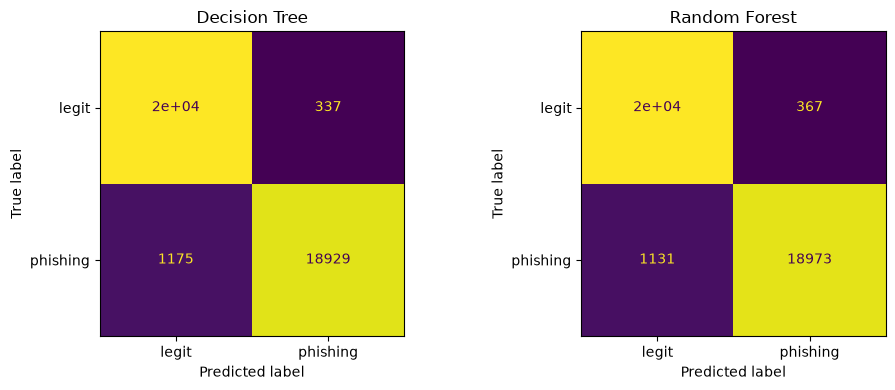

In [8]:
fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4))
for ax, (name, m) in zip(np.atleast_1d(axes), models.items()):
    ConfusionMatrixDisplay.from_estimator(
        m, X_test, y_test, display_labels=['legit', 'phishing'], ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 6. Pilih model

Pilih yang false positive rate-nya rendah dengan recall yang masih bagus.

In [9]:
CHOSEN = 'Random Forest'  # ganti ke 'Decision Tree' kalau ingin model paling sederhana
model = models[CHOSEN]
print(f'Model terpilih: {CHOSEN}')
print()
print(classification_report(y_test, model.predict(X_test), target_names=['legit', 'phishing'], digits=4))

Model terpilih: Random Forest

              precision    recall  f1-score   support

       legit     0.9458    0.9817    0.9634     20104
    phishing     0.9810    0.9437    0.9620     20104

    accuracy                         0.9627     40208
   macro avg     0.9634    0.9627    0.9627     40208
weighted avg     0.9634    0.9627    0.9627     40208



## 7. Analisis ambang (threshold)

Di ekstensi, skor risiko = peluang × 100 (dibulatkan), lalu:

| Skor | Level |
|---|---|
| < `warn` | 🟢 Aman, tanpa gangguan |
| ≥ `warn` | 🟡 Waspada: banner kecil, form mulai dipantau |
| ≥ `danger` | 🔴 Berbahaya |

Titik awal rancangan: `warn = 40`, `danger = 70`. Tabel di bawah menunjukkan dampak tiap ambang pada data uji.

Catatan: ekstensi juga menambah poin heuristik (redirect, link pendek, umur domain) di atas skor model, lihat `extension/config.js`.

In [10]:
proba_test = positive_proba(model, X_test)
y_true = y_test.to_numpy()
score_test = np.floor(proba_test * 100 + 0.5)  # sama dengan Math.round di JavaScript

rows = []
for t in range(30, 95, 5):
    pred = (score_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    rows.append({
        'ambang (%)': t,
        'false positive rate': fp / (fp + tn) if fp + tn else 0.0,
        'recall (phishing tertangkap)': tp / (tp + fn) if tp + fn else 0.0,
        'precision': tp / (tp + fp) if tp + fp else np.nan,
    })
pd.DataFrame(rows).set_index('ambang (%)').style.format('{:.4f}')

,false positive rate,recall (phishing tertangkap),precision
ambang (%),,,
30,0.0371,0.9527,0.9625
35,0.0294,0.9491,0.9700
40,0.0223,0.9464,0.9770
45,0.0199,0.9446,0.9794
50,0.0183,0.9437,0.9810
55,0.0149,0.9398,0.9844
60,0.0131,0.9373,0.9862
65,0.0108,0.9319,0.9886
70,0.0082,0.9278,0.9913


In [11]:
# Saran ambang berdasarkan batas false positive yang masih bisa diterima
TARGET_FPR_WARN = 0.05    # maksimal 5% situs legit mendapat banner Waspada
TARGET_FPR_DANGER = 0.01  # maksimal 1% situs legit mendapat label Berbahaya

legit_scores = score_test[y_true == 0]
suggest_warn = int(np.clip(np.quantile(legit_scores, 1 - TARGET_FPR_WARN) + 1, 1, 99))
suggest_danger = int(np.clip(max(np.quantile(legit_scores, 1 - TARGET_FPR_DANGER) + 1, suggest_warn + 1), 2, 100))
print(f'Saran ambang: warn = {suggest_warn}, danger = {suggest_danger}')

# Default = titik awal rancangan. Ganti dengan saran di atas kalau setuju.
THRESHOLDS = {'warn': 40, 'danger': 70}
# THRESHOLDS = {'warn': suggest_warn, 'danger': suggest_danger}
print('Ambang yang akan diekspor:', THRESHOLDS)

Saran ambang: warn = 24, danger = 67
Ambang yang akan diekspor: {'warn': 40, 'danger': 70}


## 8. Fitur paling berpengaruh

Berguna sebagai bahan penjelasan ke juri.

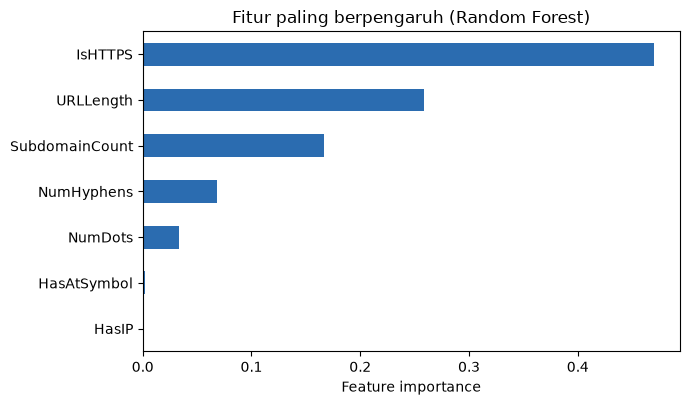

In [12]:
importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
ax = importance.plot.barh(figsize=(7, 0.45 * len(FEATURES) + 1), color='#2b6cb0')
ax.set_xlabel('Feature importance')
ax.set_title(f'Fitur paling berpengaruh ({CHOSEN})')
plt.tight_layout()
plt.show()

## 9. Uji dengan URL di luar dataset

Dataset sering tidak mewakili kondisi nyata (rancangan bagian 15). Contoh: di beberapa dataset, URL legit hampir semuanya hanya halaman depan (`https://www.situs.com`), sehingga model belajar bahwa URL panjang = phishing.

Cek dengan URL legit yang punya path panjang, dan tambahkan URL dari kampus/instansimu sendiri.

In [13]:
SANITY_URLS = {
    # Legit dengan path panjang: jangan sampai dianggap phishing
    'https://www.its.ac.id/informatika/id/beranda/': 0,
    'https://github.com/scikit-learn/scikit-learn/blob/main/README.rst': 0,
    'https://id.wikipedia.org/wiki/Institut_Teknologi_Sepuluh_Nopember': 0,
    'https://docs.python.org/3/library/urllib.parse.html#url-parsing': 0,
    'https://www.tokopedia.com/search?st=product&q=laptop%20gaming': 0,
    'https://news.ycombinator.com/item?id=1': 0,
    # Pola mencurigakan (contoh buatan, bukan situs nyata)
    'http://192.168.10.5/login/verify.php': 1,
    'http://secure-login-bank-update.example-verify.com/account/confirm': 1,
    'https://login.secure.account.verify.example.xyz/signin?session=8f7a6c': 1,
    'http://bank.example@203.0.113.7/login': 1,
    'http://login-kampus-verifikasi.free-host.test:8000/fake-login/': 1,
}

sanity = EX.features_frame(SANITY_URLS, FEATURES)
sanity_proba = positive_proba(model, sanity)
pd.DataFrame({
    'url': list(SANITY_URLS),
    'harapan': ['phishing' if v else 'legit' for v in SANITY_URLS.values()],
    'skor model (%)': np.floor(sanity_proba * 100 + 0.5).astype(int),
})

,url,harapan,skor model (%)
0,https://www.its.ac.id/informatika/id/beranda/,legit,84
1,https://github.com/scikit-learn/scikit-learn/b...,legit,99
2,https://id.wikipedia.org/wiki/Institut_Teknolo...,legit,95
3,https://docs.python.org/3/library/urllib.parse...,legit,97
4,https://www.tokopedia.com/search?st=product&q=...,legit,95
5,https://news.ycombinator.com/item?id=1,legit,21
6,http://192.168.10.5/login/verify.php,phishing,100
7,http://secure-login-bank-update.example-verify...,phishing,100
8,https://login.secure.account.verify.example.xy...,phishing,97
9,http://bank.example@203.0.113.7/login,phishing,100


## 10. Simpan & ekspor ke ekstensi

Sel di bawah menyimpan `artifacts/model.joblib`, lalu menulis:
- `extension/model/model.json`: model yang dijalankan di browser
- `extension/model/test_vectors.json`: contoh URL + hasil Python, untuk dicocokkan di halaman uji ekstensi

Sebelum menulis, hasil JSON dicek harus sama persis dengan scikit-learn.

In [14]:
metrics = {k: round(float(v), 4) for k, v in evaluate(model, X_test, y_test).items()}
bundle = {
    'model': model,
    'features': FEATURES,
    'thresholds': THRESHOLDS,
    'metrics': metrics,
    'dataset': {
        'file': DATA_PATH.name,
        'n_train': int(len(X_train)),
        'n_test': int(len(X_test)),
        'phishing_ratio': round(float(y.mean()), 4),
    },
    'created_at': datetime.datetime.now().isoformat(timespec='seconds'),
}
joblib.dump(bundle, ARTIFACTS / 'model.joblib')
print('Tersimpan:', ARTIFACTS / 'model.joblib')
metrics

Tersimpan: /home/archer/Projects/phising-project-blocker/ml/artifacts/model.joblib


{'accuracy': 0.9627,
 'precision': 0.981,
 'recall': 0.9437,
 'f1': 0.962,
 'roc_auc': 0.9863,
 'false_positive_rate': 0.0183,
 'false_negative_rate': 0.0563}

In [15]:
verify_X = X_test.sample(n=min(len(X_test), 2000), random_state=RANDOM_STATE)
payload = EX.export_bundle(bundle, verify_X=verify_X)

legit_urls = url_test[y_test == 0]
phish_urls = url_test[y_test == 1]
vector_urls = (
    legit_urls.sample(n=min(100, len(legit_urls)), random_state=RANDOM_STATE).tolist()
    + phish_urls.sample(n=min(100, len(phish_urls)), random_state=RANDOM_STATE).tolist()
    + list(SANITY_URLS)
)
EX.write_test_vectors(bundle, payload, vector_urls)

✓ Verifikasi JSON vs scikit-learn: 2,017 baris, selisih maks 3.33e-16
✓ Model tersimpan: /home/archer/Projects/phising-project-blocker/extension/model/model.json (420 KB, 60 pohon, 20,490 node, model_id e571bd653dad)
✓ Test vector tersimpan: /home/archer/Projects/phising-project-blocker/extension/model/test_vectors.json (227 URL)


## 11. Langkah berikutnya

1. Buka `chrome://extensions` lalu klik ⟳ (reload) pada PhishShield.
2. Klik ikon PhishShield → **Pengaturan & model** → **Uji kecocokan model**. Semua baris harus cocok.
3. Coba skenario di `demo/README.md`, lalu buka situs-situs normal untuk mengecek false positive.
4. Kalau false positive terlalu banyak: naikkan ambang, tambah whitelist, atau latih ulang dengan data legit yang lebih beragam.